# Eksploracja danych — brakujące wartości

**Cel zajęć:** nauczyć się *znajdować* braki (także te ukryte), *diagnozować*, czy są przypadkowe, i *świadomie wybierać*, czy je usunąć, czy uzupełnić.

**Plan:**
1. Rozgrzewka na zbiorze **Titanic** — te same kroki co na wykładzie.
2. Zadanie główne: **oferty mieszkań** (`nieruchomosci.csv`) — prawdziwy bałagan.

**Zadania:** 🟢 podstawowe (obowiązkowe), 🔵 dla ambitnych.

**Jak pracować:** w Colabie wybierz *Plik → Zapisz kopię na Dysku*, wgraj plik `nieruchomosci.csv` (ikona folderu po lewej → *Prześlij*), rozwiąż zadania w miejscach `# TODO`, a gotowy notatnik umieść w swoim repozytorium na GitHubie.

In [ ]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams.update({"figure.figsize": (7, 4), "font.size": 11})

URL_TITANIC = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
titanic = pd.read_csv("titanic.csv") if Path("titanic.csv").exists() else pd.read_csv(URL_TITANIC)

if not Path("nieruchomosci.csv").exists():
    print("⚠️ Wgraj plik nieruchomosci.csv do bieżącego katalogu (w Colabie: ikona folderu → Prześlij).")

print(titanic.shape)
titanic.head()

(891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


---
# Część 1. Rozgrzewka: Titanic

| kolumna | znaczenie |
|---|---|
| `Survived` | czy pasażer przeżył (1 = tak) |
| `Pclass` | klasa biletu (1, 2, 3) |
| `Sex`, `Age` | płeć, wiek |
| `SibSp`, `Parch` | liczba rodzeństwa/małżonków oraz rodziców/dzieci na pokładzie |
| `Fare` | cena biletu (£) |
| `Cabin` | numer kabiny |
| `Embarked` | port zaokrętowania: C — Cherbourg, Q — Queenstown, S — Southampton |

### 🟢 Zadanie 1: ile jest braków?

1. Policz liczbę i odsetek braków w każdej kolumnie. Pokaż tylko kolumny, w których braki występują, posortowane malejąco.
2. Narysuj poziomy wykres słupkowy odsetka braków (`.plot.barh()`), z opisem osi.

,0
Cabin,687
Age,177
Embarked,2


,0
Cabin,0.771044
Age,0.198653
Embarked,0.002245


Text(0, 0.5, 'Kolumna')

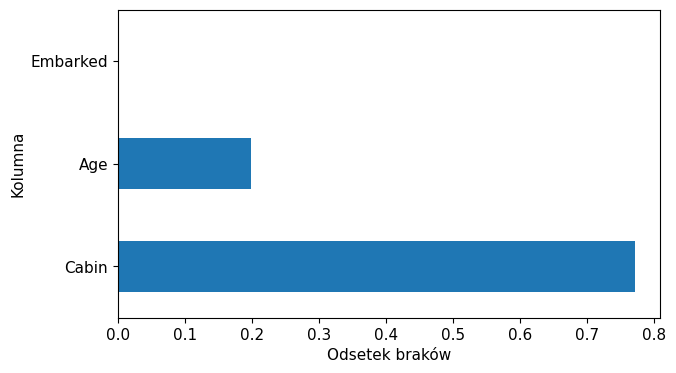

In [ ]:
# TODO
naCount = titanic.isna().sum()
naCount = naCount[naCount > 0].sort_values(ascending=False)
display(naCount)

naPercentage = naCount / len(titanic)
display(naPercentage)

plot_braki = naPercentage.plot.barh()
plot_braki.set_xlabel("Odsetek braków")
plot_braki.set_ylabel("Kolumna")


### 🟢 Zadanie 2: mapa braków

Narysuj mapę braków (`sns.heatmap(titanic.isna(), cbar=False)`) dla kolumn `Age`, `Cabin`, `Embarked` — najpierw z wierszami w oryginalnej kolejności, a potem **posortowanymi według klasy** (`Pclass`). Dwa wykresy obok siebie.

Co widać na drugim wykresie, czego nie było widać na pierwszym?

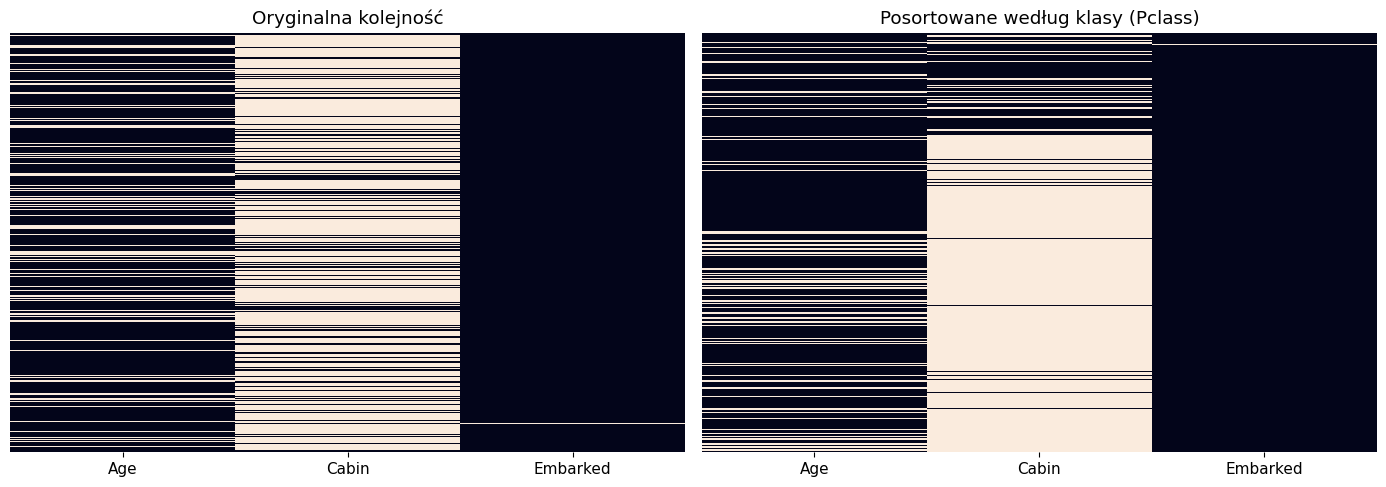

In [ ]:
kolumny = ["Age", "Cabin", "Embarked"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.heatmap(titanic[kolumny].isna(), cbar=False, yticklabels=False, ax=axes[0])
axes[0].tick_params(left=False)
axes[0].set_title("Oryginalna kolejność")

titanic_sorted = titanic.sort_values("Pclass")
sns.heatmap(titanic_sorted[kolumny].isna(), cbar=False, yticklabels=False, ax=axes[1])
axes[1].tick_params(left=False)
axes[1].set_title("Posortowane według klasy (Pclass)")

plt.tight_layout()
plt.show()

*Twoja odpowiedź:* W danych na drugim wykresie widać silną zależność pomiędzy przydzieleniem kabiny w zbiorze a klasą.

### 🟢 Zadanie 3: czy braki wieku są losowe?

1. Utwórz serię `brak_wieku = titanic["Age"].isna()`.
2. Policz odsetek braków wieku w każdej klasie i osobno dla każdej płci.
3. Porównaj odsetek ocalałych wśród osób ze znanym wiekiem i bez wieku.
4. Narysuj wyniki z punktów 2 i 3 na dwóch wykresach słupkowych.
5. Czy braki wieku to MCAR? Co by się stało z odsetkiem ocalałych, gdybyśmy usunęli wiersze bez wieku?

Pclass  Sex   
1       female    0.095745
        male      0.172131
2       female    0.026316
        male      0.083333
3       female    0.291667
        male      0.270893
Name: Age, dtype: float64

,Age
Pclass,
1,0.138889
2,0.059783
3,0.276986


,Age
Sex,
female,0.168790
male,0.214905


,Survived
Age,
False,0.406162
True,0.293785


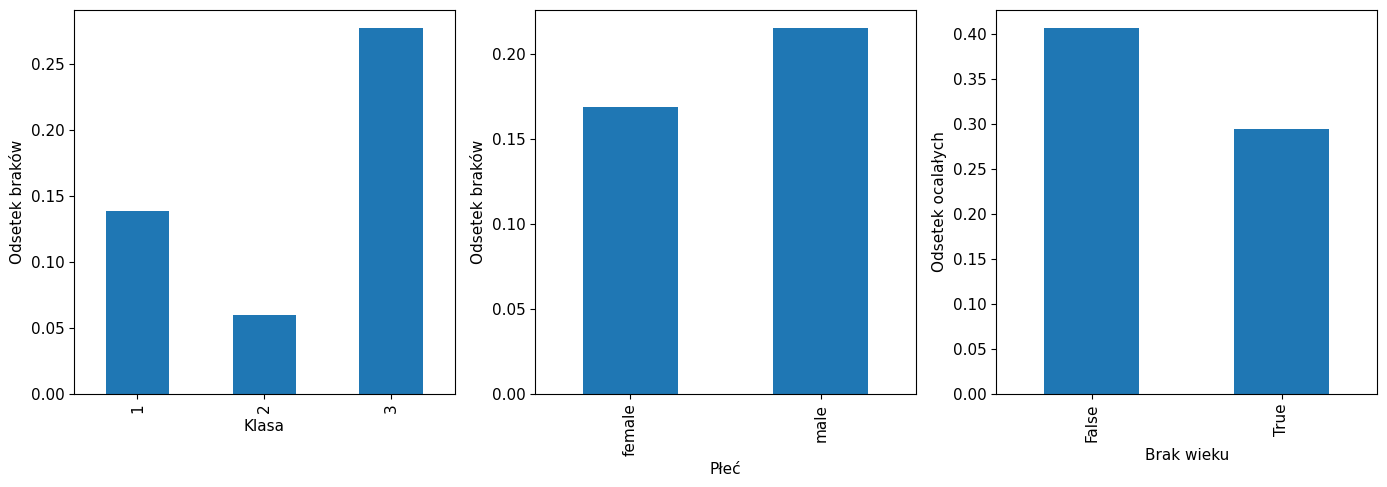

In [ ]:
brak_wieku = titanic["Age"].isna()

brak_wieku_odsetek = brak_wieku.groupby([titanic["Pclass"], titanic["Sex"]]).mean()
display(brak_wieku_odsetek)

brak_wieku_klasa = brak_wieku.groupby(titanic["Pclass"]).mean()
display(brak_wieku_klasa)

brak_wieku_plec = brak_wieku.groupby(titanic["Sex"]).mean()
display(brak_wieku_plec)

znany_wiek_ocalali = titanic.groupby(brak_wieku)["Survived"].mean()
display(znany_wiek_ocalali)

fig, axes = plt.subplots(1, 3, figsize=(14, 5))

brak_wieku_klasa.plot.bar(ax=axes[0])
axes[0].set_ylabel("Odsetek braków")
axes[0].set_xlabel("Klasa")

brak_wieku_plec.plot.bar(ax=axes[1])
axes[1].set_ylabel("Odsetek braków")
axes[1].set_xlabel("Płeć")

znany_wiek_ocalali.plot.bar(ax=axes[2])
axes[2].set_ylabel("Odsetek ocalałych")
axes[2].set_xlabel("Brak wieku")

plt.tight_layout()
plt.show()

*Twoja odpowiedź:* Z wykresów widac, że to nie MCAR, a gdybyśmy usuneli osoby bez wieku, odsetek ocalałych wzrośnie.

### 🟢 Zadanie 4: ile kosztuje usuwanie?

Dla czterech wariantów — bez zmian, `dropna(subset=["Embarked"])`, `dropna(subset=["Age"])`, `dropna()` — zbuduj tabelę z kolumnami:
- liczba wierszy,
- odsetek ocalałych,
- odsetek pasażerów 1. klasy.

Który wariant najbardziej zniekształca dane i dlaczego?

In [ ]:
warianty = {
    "bez zmian": titanic,
    # TODO: pozostałe warianty
    "dropna(subset=['Embarked'])": titanic.dropna(subset=["Embarked"]),
    "dropna(subset=['Age'])": titanic.dropna(subset=["Age"]),
    "dropna()": titanic.dropna(),
}

# TODO: tabela
tabela = pd.DataFrame(columns=["Liczba wierszy", "Odsetek ocalałych", "Odsetek pasażerów 1. klasy"])
for nazwa, dane in warianty.items():
    liczba_wierszy = len(dane)
    odsetek_ocalali = dane["Survived"].mean()
    odsetek_klasy = (dane["Pclass"] == 1).mean()
    tabela.loc[nazwa] = [liczba_wierszy, odsetek_ocalali, odsetek_klasy]
tabela

,Liczba wierszy,Odsetek ocalałych,Odsetek pasażerów 1. klasy
bez zmian,891.0,0.383838,0.242424
dropna(subset=['Embarked']),889.0,0.382452,0.240720
dropna(subset=['Age']),714.0,0.406162,0.260504
dropna(),183.0,0.672131,0.863388


*Twoja odpowiedź:* Wariant dropna() zniekształca najbardziej dane, bo usuwa ich najwięcej, a większość istniejących danych bez braków dotyczy pasażerów tylko 1. klasy.

### 🟢 Zadanie 5: uzupełnianie wieku

1. **Najpierw** dodaj kolumnę-flagę `Age_brak`.
2. Utwórz dwie wersje kolumny wieku:
   - `wiek_srednia` — braki uzupełnione średnią,
   - `wiek_grupy` — braki uzupełnione medianą w grupach (klasa × płeć); wskazówka: `groupby(...)["Age"].transform("median")`.
3. Narysuj trzy histogramy obok siebie (te same przedziały, `bins=np.arange(0, 82, 2)`): znane wartości, `wiek_srednia`, `wiek_grupy`.
4. Porównaj odchylenia standardowe. Która metoda bardziej zniekształca rozkład?

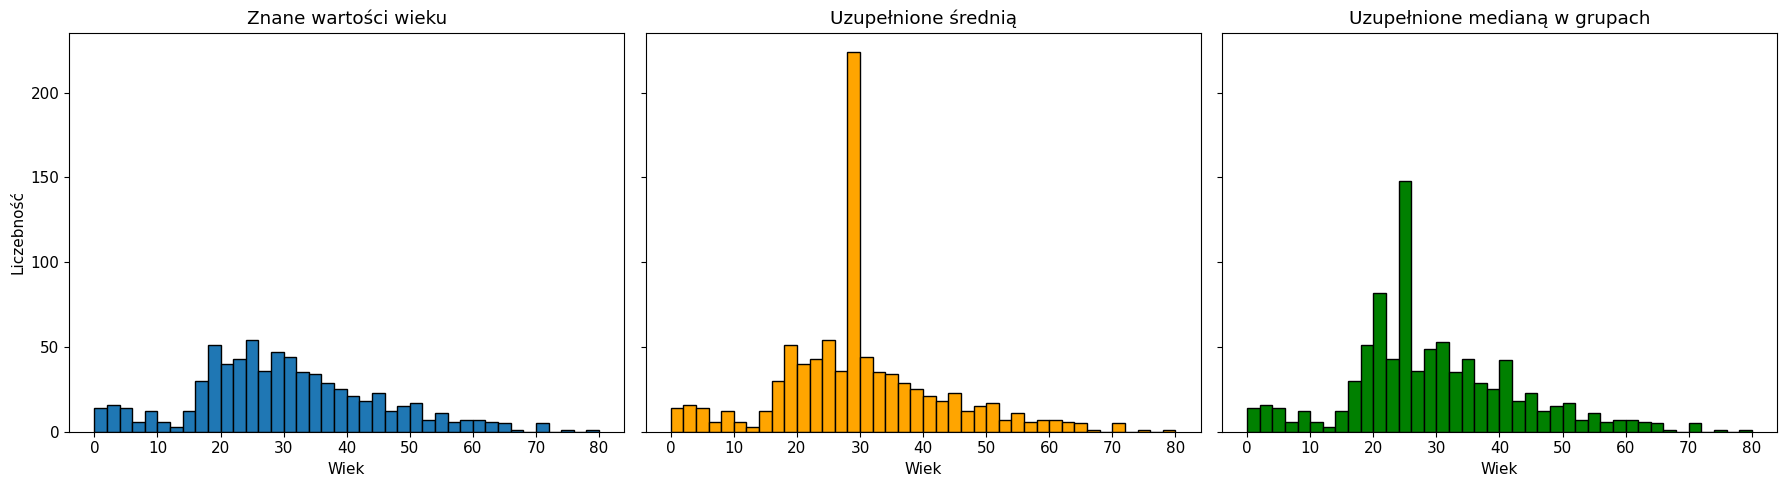

Odchylenia standardowe:
Oryginalny wiek (bez braków): 14.5265
Uzupełnione średnią:          13.0020
Uzupełnione medianą w grupach: 13.3044


In [ ]:
# TODO
titanic["Age_brak"] = titanic["Age"].isna()
titanic["wiek_srednia"] = titanic["Age"].fillna(titanic["Age"].mean())
titanic["wiek_grupy"] = titanic["Age"].fillna(titanic.groupby(["Pclass", "Sex"])["Age"].transform("median"))

bins = np.arange(0, 82, 2)
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)

titanic["Age"].dropna().plot.hist(bins=bins, ax=axes[0], edgecolor="black")
axes[0].set_title("Znane wartości wieku")
axes[0].set_xlabel("Wiek")
axes[0].set_ylabel("Liczebność")

titanic["wiek_srednia"].plot.hist(bins=bins, ax=axes[1], color="orange", edgecolor="black")
axes[1].set_title("Uzupełnione średnią")
axes[1].set_xlabel("Wiek")

titanic["wiek_grupy"].plot.hist(bins=bins, ax=axes[2], color="green", edgecolor="black")
axes[2].set_title("Uzupełnione medianą w grupach")
axes[2].set_xlabel("Wiek")

plt.tight_layout()
plt.show()

print("Odchylenia standardowe:")
print(f"Oryginalny wiek (bez braków): {titanic['Age'].std():.4f}")
print(f"Uzupełnione średnią:          {titanic['wiek_srednia'].std():.4f}")
print(f"Uzupełnione medianą w grupach: {titanic['wiek_grupy'].std():.4f}")

*Twoja odpowiedź:* Rozkład najabrdziej zniekształca grupa, w której niezależnie od klasy nadajemy osobom bez wieku średnią.

### 🔵 Zadanie 6 (dla ambitnych): imputacja modelem

Uzupełnij wiek za pomocą `IterativeImputer` z biblioteki scikit-learn, wykorzystując kolumny `Pclass`, `SibSp`, `Parch`, `Fare` oraz płeć zakodowaną jako 0/1. Porównaj histogram i odchylenie standardowe z wynikami zadania 5.

```python
from sklearn.experimental import enable_iterative_imputer  # wymagane!
from sklearn.impute import IterativeImputer
```

In [ ]:
# TODO

---
# Część 2. Zadanie główne: oferty mieszkań

**Dane:** plik `nieruchomosci.csv` — 45 ofert sprzedaży mieszkań w pięciu miastach.

| kolumna | znaczenie |
|---|---|
| `powierzchnia` | powierzchnia mieszkania [m²] |
| `rok_budowy` | rok budowy budynku |
| `pietro`, `liczba_pieter` | piętro mieszkania (0 = parter) i liczba pięter budynku |
| `parking`, `balkon` | Tak / Nie |
| `stan` | stan mieszkania |
| `cena_m2`, `cena_total` | cena za m² i cena całkowita [zł] |

Plik przygotował ktoś, kto różne braki zapisywał na różne sposoby. Twoim zadaniem jest je znaleźć i rozsądnie obsłużyć.

### 🟢 Zadanie 7: pierwszy rzut oka

1. Wczytaj plik bez żadnych dodatkowych parametrów i sprawdź typy kolumn (`dtypes`).
2. Policz braki (`isna().sum()`). Ile braków widzi pandas?
3. Dlaczego kolumna `powierzchnia` nie jest liczbowa, choć zawiera powierzchnię w m²?

In [ ]:
mieszkania = pd.read_csv("nieruchomosci.csv")

# TODO
display(mieszkania.dtypes)
display(mieszkania.isna().sum())
display(mieszkania["powierzchnia"].unique())

,0
id,int64
miasto,object
dzielnica,object
powierzchnia,object
liczba_pokoi,int64
rok_budowy,object
pietro,object
liczba_pieter,int64
parking,object
balkon,object


,0
id,0
miasto,0
dzielnica,0
powierzchnia,4
liczba_pokoi,0
rok_budowy,4
pietro,0
liczba_pieter,0
parking,0
balkon,0


array(['65', '48', '72', '55', '80', nan, '60', '45', '70', '90', '58',
       '52', '68', '0', '75', '62', '50', 'brak', '66', '85', '54', '95',
       '56', '42', '78', '88', '64', '51', '69', '46', '82', '76'],
      dtype=object)

*Twoja odpowiedź:* Pandas znajduje po 4 braki dla powierzchni i roku budowy. W kolumnie `powierzchnia` oprócz pól `NaN` wykrytych przez pandas za to znajdują się pola o nazwia `brak`, które są stringami, a więc siłą rzeczy nie mogą być zmiennymi liczbowymi.

### 🟢 Zadanie 8: braki „w przebraniu”

1. Dla każdej kolumny tekstowej i każdej kolumny liczbowej obejrzyj występujące wartości (`value_counts(dropna=False)` albo `unique()`). Wypisz wszystkie wartości, które oznaczają brak.
2. **Pułapka:** w kolumnach `powierzchnia` i `pietro` występuje `0`. Czy w obu przypadkach to brak danych?
3. Wczytaj plik ponownie z parametrem `na_values` podanym jako **słownik** (kolumna → lista wartości), tak aby każda kolumna miała tylko „swoje” oznaczenia braków.
4. Sprawdź typy kolumn i policz braki jeszcze raz.

In [ ]:
# TODO

for kolumna in mieszkania.columns:
    if mieszkania[kolumna].dtype == object:
        #print(f"{kolumna}:")
        print(mieszkania[kolumna].value_counts(dropna=False))
    else:
        print(f"{kolumna}:")
        print(mieszkania[kolumna].unique())
    print('\n')


id:
[ 1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24
 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45]


miasto
Warszawa    9
Kraków      9
Wrocław     9
Poznań      9
Gdańsk      9
Name: count, dtype: int64


dzielnica
Krzyki           2
Stare Miasto     2
Grunwald         2
Śródmieście      2
Mokotów          1
Wrzeszcz         1
Krowodrza        1
Podgórze         1
Jeżyce           1
Oliwa            1
Żoliborz         1
Kazimierz        1
Psie Pole        1
Rataje           1
Siedlce          1
Praga            1
Nowa Huta        1
Fabryczna        1
Wilda            1
Przymorze        1
Ochota           1
Bronowice        1
Centrum          1
Ursynów          1
Dębniki          1
Zaspa            1
Wilanów          1
Łagiewniki       1
Biskupin         1
Sołacz           1
Chełm            1
Bielany          1
Ruczaj           1
Gaj              1
Główna           1
Morena           1
Targówek         1
Mistrzejowice    1
Ołbin            1


*Twoja odpowiedź:*
1. `powierzchnia`: `NaN` lub `0` lub `brak`
2. `rok_budowy`: `NaN` lub `brak`
3. `pietro`: `-999` lub `brak`
4. `parking`: `?`
5. `balkon`: `?`
6. `cena_m2`: `-999` lub `-1`

Piętro może być parterem, więc 0 jest wartością prawidłową.

In [ ]:
braki_slownik = {
    "powierzchnia": ["brak", "0"],
    # TODO: pozostałe kolumny
    "rok_budowy": ["brak"],
    "pietro": ["-999", "brak"],
    "parking": ["?"],
    "balkon": ["?"],
    "cena_m2": ["-999", "-1"]
}

mieszkania = pd.read_csv("nieruchomosci.csv", na_values=braki_slownik)
# TODO: typy i liczba braków
display(mieszkania.dtypes)
display(mieszkania.isna().sum())

,0
id,int64
miasto,object
dzielnica,object
powierzchnia,float64
liczba_pokoi,int64
rok_budowy,float64
pietro,float64
liczba_pieter,int64
parking,object
balkon,object


,0
id,0
miasto,0
dzielnica,0
powierzchnia,9
liczba_pokoi,0
rok_budowy,7
pietro,3
liczba_pieter,0
parking,5
balkon,3


### 🟢 Zadanie 9: dziwna kategoria

Obejrzyj wartości w kolumnie `stan`. Jedna z nich nie pasuje do pozostałych. Co mogła oznaczać i jak ją poprawić? Zaproponuj i zastosuj rozwiązanie (uzasadnij je).

In [ ]:
# TODO
# Dziwna kategoria jest po prostu nieprzetłumaczonym chińskim słowem
# odpawiadającym kategorii `bardzo dobry`, więc możemy ją zastąpić.

mieszkania["stan"] = mieszkania["stan"].replace("很好", "Bardzo dobry")

print(mieszkania["stan"].value_counts(dropna=False))

display(mieszkania)

stan
Dobry           28
Bardzo dobry    12
Do remontu       5
Name: count, dtype: int64


,id,miasto,dzielnica,powierzchnia,liczba_pokoi,rok_budowy,pietro,liczba_pieter,parking,balkon,stan,cena_m2,cena_total
0,1,Warszawa,Mokotów,65.0,3,2015.0,4.0,10,Tak,Tak,Dobry,12500.0,812500
1,2,Kraków,Krowodrza,48.0,2,NaN,2.0,5,Nie,Tak,Bardzo dobry,10200.0,489600
2,3,Wrocław,Krzyki,72.0,3,2010.0,NaN,4,Tak,Nie,Dobry,9800.0,705600
3,4,Poznań,Grunwald,55.0,2,2018.0,3.0,8,Tak,Tak,Bardzo dobry,11000.0,605000
4,5,Gdańsk,Wrzeszcz,80.0,4,1998.0,1.0,3,NaN,Tak,Do remontu,8500.0,680000
5,6,Warszawa,Śródmieście,NaN,2,2020.0,7.0,12,Tak,Tak,Bardzo dobry,15000.0,1200000
6,7,Kraków,Podgórze,60.0,3,2005.0,0.0,6,Tak,Nie,Dobry,9500.0,570000
7,8,Wrocław,Stare Miasto,45.0,1,2019.0,5.0,9,Nie,Tak,Bardzo dobry,11500.0,517500
8,9,Poznań,Jeżyce,70.0,3,NaN,2.0,4,Tak,Tak,Dobry,10500.0,735000
9,10,Gdańsk,Oliwa,90.0,4,2001.0,1.0,2,Tak,Tak,Dobry,9000.0,810000


### 🟢 Zadanie 10: mapa braków

1. Narysuj odsetek braków w kolumnach (wykres słupkowy) i mapę braków.
2. Czy braki w różnych kolumnach występują w tych samych wierszach? (Wskazówka: `mieszkania.isna().corr()` dla kolumn z brakami.)

,powierzchnia,rok_budowy,pietro,parking,balkon,cena_m2
powierzchnia,1.000000e+00,-0.214599,-0.133631,-4.170558e-17,-0.133631,-0.107833
rok_budowy,-2.145988e-01,1.000000,-0.114708,4.335550e-02,0.131095,-0.092563
pietro,-1.336306e-01,-0.114708,1.000000,-9.449112e-02,-0.071429,-0.057639
parking,-4.170558e-17,0.043355,-0.094491,1.000000e+00,-0.094491,-0.076249
balkon,-1.336306e-01,0.131095,-0.071429,-9.449112e-02,1.000000,-0.057639
cena_m2,-1.078328e-01,-0.092563,-0.057639,-7.624929e-02,-0.057639,1.000000


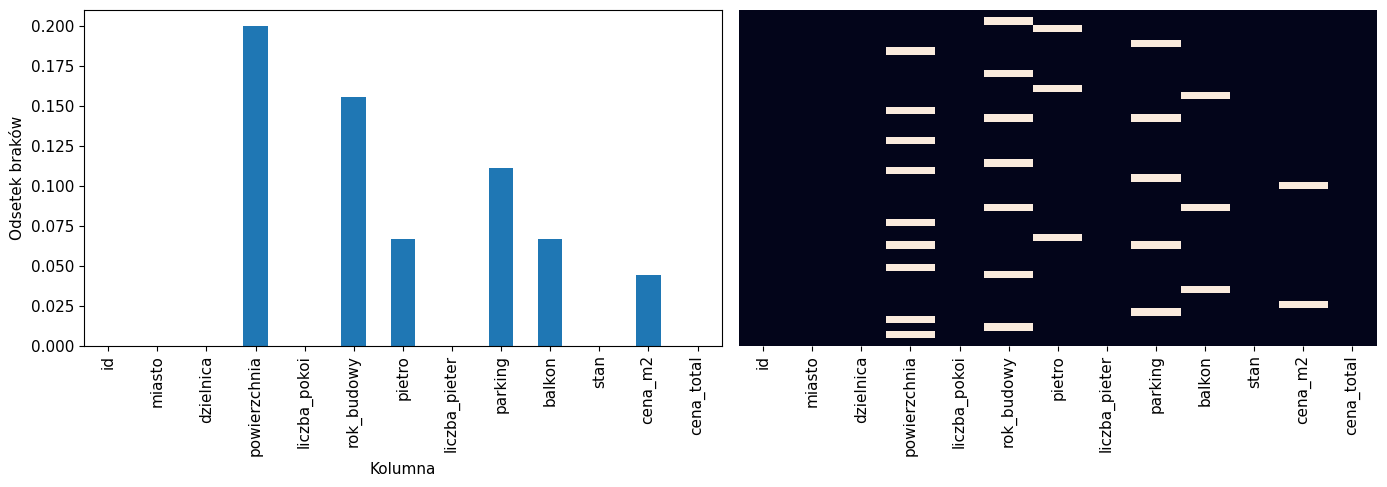

In [ ]:
# TODO

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

(mieszkania.isna().sum() / len(mieszkania)).plot.bar(ax=axes[0])
axes[0].set_ylabel("Odsetek braków")
axes[0].set_xlabel("Kolumna")

sns.heatmap(mieszkania.isna(), cbar=False, yticklabels=False, ax=axes[1])
axes[1].tick_params(left=False)

# Filtrowanie kolumn, które mają jakiekolwiek braki danych przed obliczeniem korelacji
kolumny_z_brakami = mieszkania.columns[mieszkania.isna().any()]
display(mieszkania[kolumny_z_brakami].isna().corr())

plt.tight_layout()
plt.show()

*Twoja odpowiedź:* Analizując macierz korelacji `mieszkania.isna().corr()` oraz mapę braków, możemy wywnioskować, że braki w różnych kolumnach niekoniecznie występują w tych samych wierszach. Współczynniki korelacji między brakami w poszczególnych kolumnach są bardzo niskie (bliskie zeru lub ujemne), co oznacza, że występowanie braku w jednej kolumnie nie wiąże się z jednoczesnym brakiem danych w innej kolumnie w tym samym wierszu.

### 🟢 Zadanie 11: odtwórz, zamiast zgadywać

Sprawdź, czy dla wierszy bez braków zachodzi zależność `cena_total = powierzchnia × cena_m2`. Jeśli tak — wykorzystaj ją, żeby **odtworzyć** brakujące wartości w kolumnach `powierzchnia` i `cena_m2`. Ile braków udało się w ten sposób usunąć?

To jest „ręczne uzupełnianie” z wykładu: znamy prawdziwą wartość, więc nie musimy jej szacować.

In [ ]:
# TODO
for indeks, wiersz in mieszkania.iterrows():
    if pd.isna(wiersz["powierzchnia"]) or pd.isna(wiersz["cena_m2"]):
        continue
    if not np.isclose(wiersz["powierzchnia"] * wiersz["cena_m2"], wiersz["cena_total"]):
        print("Znaleziono wierz, dla którego nie zachodzi zaleznosc")


for indeks, wiersz in mieszkania.iterrows():
    if pd.isna(wiersz["powierzchnia"]) and pd.isna(wiersz["cena_m2"]):
        continue

    if pd.isna(wiersz["cena_m2"]):
        mieszkania.at[indeks, "cena_m2"] = wiersz["cena_total"] / wiersz["powierzchnia"]

    if pd.isna(wiersz["powierzchnia"]):
        mieszkania.at[indeks, "powierzchnia"] = wiersz["cena_total"] / wiersz["cena_m2"]

print(mieszkania.isna().sum())

# Usunęliśmy 11 (9+2) braków.

id               0
miasto           0
dzielnica        0
powierzchnia     0
liczba_pokoi     0
rok_budowy       7
pietro           3
liczba_pieter    0
parking          5
balkon           3
stan             0
cena_m2          0
cena_total       0
dtype: int64


### 🟢 Zadanie 12: pozostałe braki

Dla każdej z kolumn `rok_budowy`, `pietro`, `parking`, `balkon`:
1. **Najpierw** dodaj kolumnę-flagę braku (np. `rok_budowy_brak`).
2. Zdecyduj, co zrobić z brakami, i zaimplementuj decyzję. Do rozważenia:
   - `rok_budowy` — mediana całościowa czy mediana w grupach? Jakie grupy mają sens: `miasto` czy `stan`? Policz mediany w obu podziałach, zanim wybierzesz.
   - `pietro` — są tylko 3 braki; mediana, a może coś mądrzejszego (np. środkowe piętro budynku: `liczba_pieter // 2`)?
   - `parking`, `balkon` — dominanta czy osobna kategoria `"nieznane"`? Co się stanie z odsetkiem mieszkań z parkingiem w każdym z tych wariantów?
3. Sprawdź, że w zbiorze nie ma już braków.

In [ ]:
# TODO

for kolumna in ["rok_budowy", "pietro", "parking", "balkon"]:
    mieszkania[kolumna + "_brak"] = mieszkania[kolumna].isna()

display(mieszkania["rok_budowy"].median())
display(mieszkania.groupby("stan")["rok_budowy"].median())
display(mieszkania.groupby("miasto")["rok_budowy"].median())

mediany_po_stanie = mieszkania.groupby("stan")["rok_budowy"].transform("median").apply(lambda x: int(np.floor(x)) if not pd.isna(x) else x)
mieszkania["rok_budowy"] = mieszkania["rok_budowy"].fillna(mediany_po_stanie)

mediana_globalna = int(np.floor(mieszkania["rok_budowy"].median()))
mieszkania["rok_budowy"] = mieszkania["rok_budowy"].fillna(mediana_globalna)

mieszkania["pietro"] = mieszkania["pietro"].fillna(mieszkania["liczba_pieter"] // 2)
mieszkania["parking"] = mieszkania["parking"].fillna("nieznane")
mieszkania["balkon"] = mieszkania["balkon"].fillna("nieznane")
# Dominanta spowodowałyby tu sztuczne zawyżenie/zaniżenie odsetka mieszkań z parkingiem/balkonem

display(mieszkania.isna().sum())

2011.5

,rok_budowy
stan,
Bardzo dobry,2019.0
Do remontu,1997.0
Dobry,2010.0


,rok_budowy
miasto,
Gdańsk,2001.5
Kraków,2013.0
Poznań,2013.5
Warszawa,2015.0
Wrocław,2011.0


,0
id,0
miasto,0
dzielnica,0
powierzchnia,0
liczba_pokoi,0
rok_budowy,0
pietro,0
liczba_pieter,0
parking,0
balkon,0


### 🟢 Zadanie 13: porównaj przed i po

Wczytaj surowy plik jeszcze raz (z `na_values` z zadania 8) i porównaj z oczyszczoną wersją:
1. statystyki opisowe kolumn `powierzchnia`, `rok_budowy`, `cena_m2` (`describe()`),
2. histogram `rok_budowy` przed i po uzupełnieniu (dwa wykresy obok siebie, te same przedziały).

Czy uzupełnianie zmieniło rozkłady w istotny sposób?

,powierzchnia,rok_budowy,cena_m2
count,36.000000,38.000000,43.000000
mean,64.638889,2010.289474,10223.255814
std,13.684512,7.828941,1611.689030
min,42.000000,1995.000000,8200.000000
25%,54.750000,2004.250000,9000.000000
50%,63.000000,2011.500000,9800.000000
75%,72.750000,2016.750000,11100.000000
max,95.000000,2022.000000,15000.000000


,powierzchnia,rok_budowy,cena_m2
count,45.000000,45.000000,45.000000
mean,64.933333,2010.644444,10244.336043
std,12.755391,7.407476,1623.857997
min,42.000000,1995.000000,8200.000000
25%,56.000000,2006.000000,9000.000000
50%,62.000000,2011.000000,9800.000000
75%,72.000000,2017.000000,11200.000000
max,95.000000,2022.000000,15000.000000


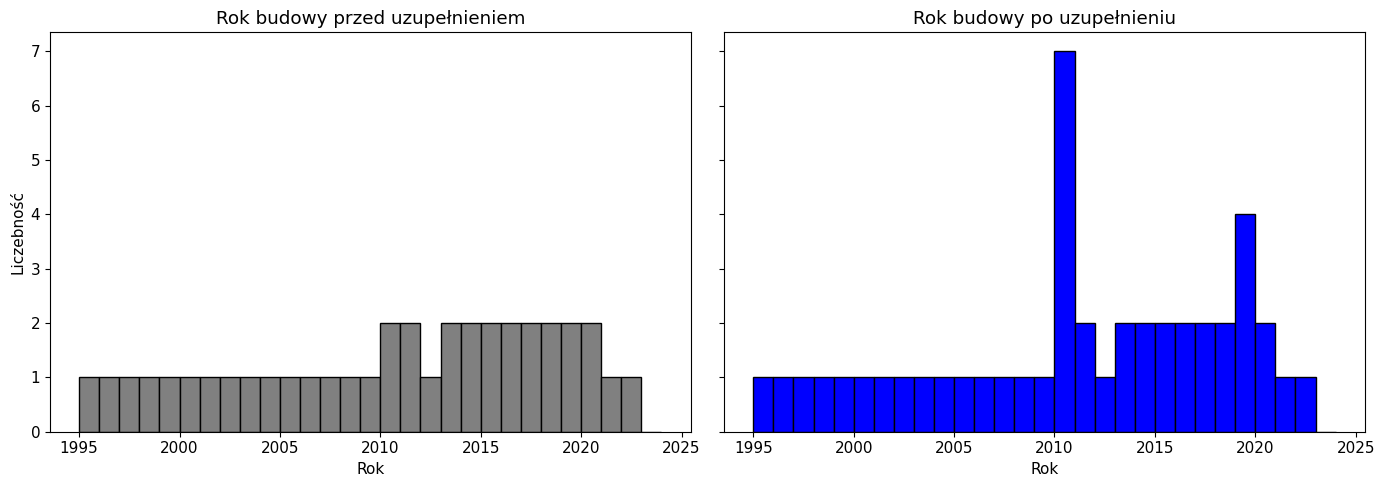

In [ ]:
mieszkania_surowe = pd.read_csv("nieruchomosci.csv", na_values=braki_slownik)

display(mieszkania_surowe[["powierzchnia", "rok_budowy", "cena_m2"]].describe())
display(mieszkania[["powierzchnia", "rok_budowy", "cena_m2"]].describe())

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

bins_rok = np.arange(1995, 2025, 1)

mieszkania_surowe["rok_budowy"].plot.hist(bins=bins_rok, ax=axes[0], color="gray", edgecolor="black")
axes[0].set_title("Rok budowy przed uzupełnieniem")
axes[0].set_xlabel("Rok")
axes[0].set_ylabel("Liczebność")

mieszkania["rok_budowy"].plot.hist(bins=bins_rok, ax=axes[1], color="blue", edgecolor="black")
axes[1].set_title("Rok budowy po uzupełnieniu")
axes[1].set_xlabel("Rok")

plt.tight_layout()
plt.show()

*Twoja odpowiedź:* Nie widać istotnych zmian w samych danych liczbowych, ale na wykresie widać anomalie jeśli chodzi o rok budowy. W obranych punktach median wybranych wcześniej dla danych bez roku budowy są bardzo duże nienaturalne skupiska.

### 🟢 Zadanie 14: zapisz decyzje

Uzupełnij tabelę. Dobra analiza danych to taka, którą ktoś inny może odtworzyć.

| Kolumna | Jak zapisano braki | Liczba braków | Decyzja | Uzasadnienie |
|---|---|---|---|---|
| `powierzchnia` | `NaN`, `"brak"`, `0` | 9 | Rekonstrukcja na podstawie `cena_total` i `cena_m2` | Tą metodą odtworzyłem rzeczywiste wartości bez wprowadzania błędów szacowania. |
| `cena_m2` | `"-999"`, `"-1"` | 2 | Rekonstrukcja na podstawie `cena_total` i `powierzchnia` | Tą metodą odtworzyłem rzeczywiste wartości bez wprowadzania błędów szacowania. |
| `rok_budowy` | `NaN`, `"brak"` | 7 | Uzupełnienie medianą dla odpowiednich grup `stan` | Nowo wybudowane mają statystycznie wysoki standard w porówaniu do starszych. |
| `pietro` | `"-999"`, `"brak"` | 3 | Uzupełnienie połową liczby pięter budynku | Średnia czy mediana globalna mogłaby wprowadzać nawet niemożliwe wartości, a połowa pięter budynku jest jakkolwiek prawdopodobna. |
| `parking` | `"?"` | 5 | Uzupełnienie osobną kategorią `"nieznane"` | Nie znalazłem żadnego innego rozwiązania, które nie byłoby całkowicie sztuczne. |
| `balkon` | `"?"` | 3 | Uzupełnienie osobną kategorią `"nieznane"` | Nie znalazłem żadnego innego rozwiązania, które nie byłoby całkowicie sztuczne. |
| `stan` | jedyny "brak" to `"很好"` | 1 | Zastąpienie wartością `"Bardzo dobry"` | Wartość `"很好"` oznacza w języku chińskim "bardzo dobry". |

### 🔵 Zadanie 15 (dla ambitnych): czy wybór metody ma znaczenie?

Uzupełnij `rok_budowy` na trzy sposoby: medianą całościową, medianą w grupach według miasta i medianą w grupach według stanu. Dla każdego wariantu policz korelację `rok_budowy` z `cena_m2`. Który wariant najmniej zmienia korelację w porównaniu z danymi bez braków?

In [ ]:
# TODO

### **Analiza z Bielika**



**Kolumny i ich analiza:**

    id - Wszystkie wpisy mają ID, brak braków.
    miasto - Wszystkie wpisy mają miasto, brak braków.
    dzielnica - Wszystkie wpisy mają dzielnicę, brak braków.
    powierzchnia - Brak braków, wszystkie wpisy mają powierzchnię.
    liczba_pokoi - Brak braków, wszystkie wpisy mają liczbę pokoi.
    rok_budowy - Brakuje wartości dla kolumny "rok_budowy" w niektórych wpisach (np. wpis 2, 3, 9, 11, 14, 15, 18, 21, 24, 27, 35, 36, 42).
    pietro - Brakuje wartości dla kolumny "pietro" w niektórych wpisach (np. wpis 2, 3, 7, 8, 11, 12, 14, 15, 16, 18, 22, 23, 24, 27, 28, 33, 34, 36, 38, 41, 43, 44).
    liczba_pieter - Brakuje wartości dla kolumny "liczba_pieter" w niektórych wpisach (np. wpis 3, 11, 14, 18, 22, 24, 36).
    parking - Brakuje wartości dla kolumny "parking" w niektórych wpisach (np. wpis 5, 12, 14, 15, 17, 18, 22, 24, 27, 34, 35, 38, **41**, 42, 44).
    balkon - Brakuje wartości dla kolumny "balkon" w niektórych wpisach (np. wpis 2, 3, 5, 8, 12, 14, 15, 17, 18, 22, 24, 27, 34, 35, 38, 41, 42, 44).
    stan - Brakuje wartości dla kolumny "stan" w niektórych wpisach (np. wpis 2, 5, 12, 14, 15, 18, 22, 24, 27, 34, 35, 38, 41, 42, 44).
    cena_m2 - Brakuje wartości dla kolumny "cena_m2" w niektórych wpisach (np. wpis 2, 14, 24, 35).
    cena_total - Brakuje wartości dla kolumny "cena_total" w niektórych wpisach (np. wpis 2, 5, 14, 24, 35).

**Podsumowanie braków:**

    rok_budowy: 13 braków
    pietro: 21 braków
    liczba_pieter: 7 braków
    parking: 15 braków
    balkon: 17 braków
    stan: 15 braków
    cena_m2: 4 braki
    cena_total: 5 braków

**Wnioski:**

Najwięcej braków występuje w kolumnach pietro i balkon, co może utrudniać pełną ocenę nieruchomości. Braki w cena_m2 i cena_total są szczególnie istotne, ponieważ dotyczą kluczowych informacji finansowych.

Jeśli potrzebujesz bardziej szczegółowej analizy lub chcesz, abym sprawdził coś konkretnego, daj znać!

### 📊 Porównanie wykrytych braków danych

| Kolumna | Liczba braków (Moja analiza) | Liczba braków (Bielik) |
| :--- | :---: | :---: |
| `powierzchnia` | **9** | 0 |
| `cena_m2` | **2** | 4 |
| `rok_budowy` | **7** | 13 |
| `pietro` | **3** | 21 |
| `liczba_pieter` | **0** | 7 |
| `parking` | **5** | 15 |
| `balkon` | **3** | 17 |
| `stan` | **1** | 15 |
| `cena_total` | **0** | 5 |

Analiza Bielika jest niewiele więcej warta niż losowanie liczb, błędnie zlicza nawet nieprawidłowo znalezione braki oraz jest najprawdopodobniej niedeterministyczna. Do wykrywania braków danych lepiej sprawdzi się człowiek wykorzystujący deterministyczne skrypty.